In [1]:
#imports 

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import polars as pl
from collections import namedtuple

%matplotlib widget

In [2]:
data_coupled    = pl.read_parquet("data_complete/2026_10_16_18h29.parquet")

In [3]:
results_coupled = data_coupled.group_by(
    pl.col("f")
).agg(
    pl.col("pow1").max().alias("pow1max"),
    pl.col('Rload')
)

Ropt_coupled = []
for f in (results_coupled["f"]):
        p = results_coupled.filter(pl.col("f") == f)["pow1max"]
        d = data_coupled.filter((pl.col("f")==f) & (pl.col("pow1") == p))["Rload"]
        Ropt_coupled.append(d[0])

In [66]:
f0_d    = 130.5939102753793
w0_d    = f0_d * 2 * jnp.pi
Cpre_d  = 3.242239649667968e-09
Cpim_d  = 5.29e-11#-8.568107094320058e-10
km2_d   = 0.9238102443864471
Q_d     = 210.41495684989928
M_d     = 0.002994312076051169

f0_c    = 99.83033054106336
w0_c    = f0_c * 2 * jnp.pi
Cpre_c  = 6.521641868262603e-09
Cpim_c  = 5.29e-11#-2.4180318826950386e-10
km2_c   = 0.3121123746460482
Q_c     = 97.87822587833094
M_c     = 0.0032064689991670725

# f0_d    = 130.
# w0_d    = f0_d * 2 * jnp.pi
# Cpre_d  = 100e-09
# Cpim_d  = 0#-8.568107094320058e-10
# km2_d   = 0.3
# Q_d     = 50
# M_d     = 0.007

# f0_c    = 100.
# w0_c    = f0_c * 2 * jnp.pi
# Cpre_c  = 100e-09
# Cpim_c  = 0#-2.4180318826950386e-10
# km2_c   = 0.3
# Q_c     = 50
# M_c     = 0.007

In [67]:
frequencies_list = jnp.linspace(90, 190, 10000)
omegas_list      = frequencies_list * 2 * jnp.pi
resistances_list = jnp.logspace(jnp.log10(1e3), jnp.log10(1e7), 100)


In [68]:
ProtoParams = namedtuple('ProtoParams', ['w0', 'M', 'Q', 'Cp', 'km2'])
ManipParams = namedtuple('ManipParams', ['gamma', 'w', 'R', 'Ce', 'tau'])

ProtoDavid = ProtoParams(w0_d, M_d, Q_d, Cpre_d+1.j*Cpim_d, km2_d)
ProtoCoude = ProtoParams(w0_c, M_c, Q_c, Cpre_c+1.j*Cpim_c, km2_c)

In [69]:
def systems_signals(proto1: ProtoParams, proto2: ProtoParams, manip: ManipParams):
    """
    returns x1, x2, phi_x1, phi_x2, v1, v2, P1in, P2in
    position resonator 1, voltage resonator 1
    position resonator 2, voltage resonator 2
    computed by analytical analysis 
    for the two couples linear resonators system
    """

    w01     = proto1.w0
    M1      = proto1.M
    Q1      = proto1.Q
    Cp1     = proto1.Cp
    km2_1   = proto1.km2

    w02     = proto2.w0
    M2      = proto2.M
    Q2      = proto2.Q
    Cp2     = proto2.Cp
    km2_2   = proto2.km2

    gamma   = manip.gamma
    w       = manip.w
    R       = manip.R
    tau     = manip.tau
    Ce      = manip.Ce

    tau1    = R*Cp1
    tau2    = R*Cp2

    c1      = Ce/Cp1
    c2      = Ce/Cp2

    alpha1 = jnp.sqrt(km2_1 * M1 * w01**2 * Cp1)
    alpha2 = jnp.sqrt(km2_2 * M2 * w02**2 * Cp2)

    A1 = (Cp1*(1+c1 + 1/(tau1*1.j*w)))/alpha1
    A2 = (Cp2*(1+c2 + 1/(tau2*1.j*w)))/alpha2
    B1 = tau * c1*Cp1/alpha1
    B2 = tau * c2*Cp2/alpha2
    C1 = 1.j*w*w01/Q1+w01**2-w**2
    C2 = 1.j*w*w02/Q2+w02**2-w**2
    D1 = alpha1/M1
    D2 = alpha2/M2
    E = (C2*A1*A2+D2*A1)/B1 - C2*B2
    F = (C2*A2+D2)/B1
    
    v1 = gamma*(F+C1)/(E*C1+F*D1)
    x1 = (gamma-v1*D1)/C1
    v2 = (v1*A1-x1)/B1
    x2 = v2*A2-v1*B2
    
    phi_x1 = jnp.angle(x1)
    phi_x2 = jnp.angle(x2)
    
    phi_v1 = jnp.angle(v1)
    phi_v2 = jnp.angle(v2)
    
    i_e = 1.j*w*(v1-v2)*Ce
    phi_ie = jnp.angle(i_e)
    
    P1in = -gamma*w*M1*jnp.imag(x1)/2
    P2in = -gamma*w*M2*jnp.imag(x2)/2

    P1elec = jnp.real(alpha1*v1*jnp.conjugate(1.j*w*x1))
    P2elec = jnp.real(alpha2*v2*jnp.conjugate(1.j*w*x2))

    d1     = w01*M1/Q1
    d2     = w02*M2/Q2
    Ploss1 = d1*jnp.abs(1.j*w*x1)**2
    Ploss2 = d2*jnp.abs(1.j*w*x2)**2
    
    Ptotelec = P1elec+P2elec
    
    
    return {'x1': jnp.abs(x1), 'x2': jnp.abs(x2), 
            'phi_x1': phi_x1, 'phi_x2': phi_x2, 
            'phi_v1': phi_v1, 'phi_v2': phi_v2, 
            'phi_ie': phi_ie, 
            'v1': jnp.abs(v1), 'v2': jnp.abs(v2), 
            'P1in': P1in, 'P2in': P2in, 
            'i_e': i_e,
            'P1elec': P1elec, 'P2elec': P2elec, 
            'Ploss1': Ploss1, 'Ploss2': Ploss2,
            'Ptotelec': Ptotelec,
            'Ptotin': P1in+P2in} 

In [70]:
# vmap pour faire sur omega et r

v_wr1 = jax.vmap(
    jax.vmap(
        systems_signals,
        in_axes=(
            None, 
            None, 
            ManipParams(
                None, 
                None, 
                0, 
                None, 
                None,
            ),
        ),
    ),
    in_axes = (
        None, 
        None, 
        ManipParams(
            None, 
            0, 
            None, 
            None, 
            None,
        )
    ),
)

In [71]:
s = v_wr1(ProtoCoude, ProtoDavid, ManipParams(0.15, omegas_list, resistances_list, 10*Cpre_d, -1))

/tmp/ipykernel_994574/1359103093.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


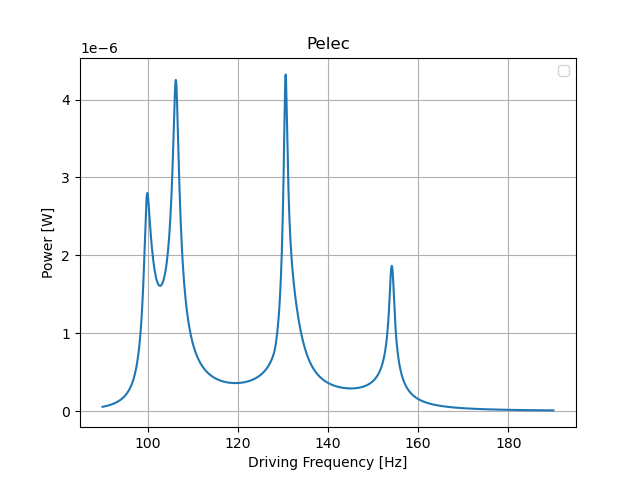

In [72]:
plt.figure()
plt.plot(frequencies_list, s['Ptotelec'].max(axis=1))
# plt.plot(frequencies_list, results_wr1['P2elec'], "c-", label = "P2")
# plt.plot(frequencies_list, results_wr1['Ptotelec'], "k--", label = "Ptot")
plt.xlabel("Driving Frequency [Hz]")
plt.ylabel("Power [W]")
plt.title("Pelec")
plt.legend()
# plt.yscale('log')
plt.grid()
plt.show()

In [73]:
def wr1_argmax_over_R(P, n1):
    idx_P = jnp.argmax(P, axis=1)
    i_opt = jnp.unravel_index(idx_P, (n1)) # unravel indices
    return i_opt # return indices
 
def extract_indices_optr1(P_np):
    nW, n1 = P_np.shape
    i_opt = wr1_argmax_over_R(P_np, n1)
    R1_opt = resistances_list[i_opt]
    return R1_opt

In [74]:
voptimize_w_r1 = jax.vmap(
    systems_signals, 
    in_axes=(
        None, 
        None, 
        ManipParams(
            None, 
            0, 
            0, 
            None, 
            None,
        )
    ),
)

In [75]:
def optimize_w_r1(proto1, proto2, manip):
    
    
    signals = v_wr1(proto1, proto2, manip)

    R1_opt_wr1 = extract_indices_optr1(signals['Ptotelec'])
    
    param = ManipParams(manip.gamma, manip.w, R1_opt_wr1, manip.Ce, manip.tau)
    
    return voptimize_w_r1(proto1, proto2, param), R1_opt_wr1

In [76]:
results_wr1, R1_opt_w_r1 = optimize_w_r1(ProtoDavid, ProtoCoude, ManipParams(0.15, omegas_list, resistances_list, 10000*100e-9, -1))

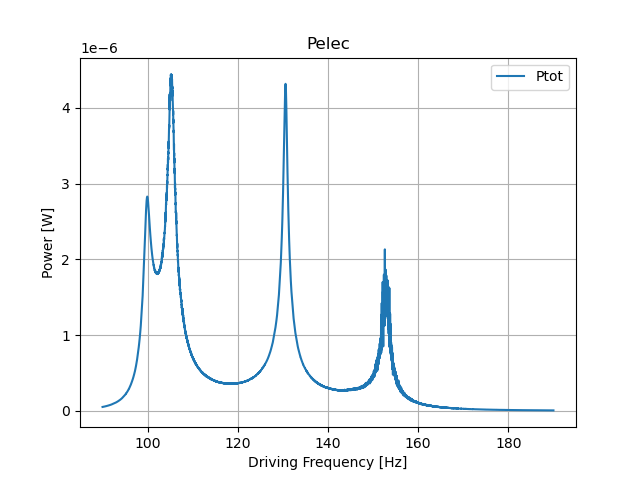

In [77]:
plt.figure()
# plt.plot(frequencies_list, results_wr1['P1elec'], label = "P1")
# plt.plot(frequencies_list, results_wr1['P2elec'], label = "P2")
plt.plot(frequencies_list, results_wr1['Ptotelec'], label = "Ptot")
plt.xlabel("Driving Frequency [Hz]")
plt.ylabel("Power [W]")
plt.title("Pelec")
plt.legend()
# plt.yscale('log')
plt.grid()
plt.show()

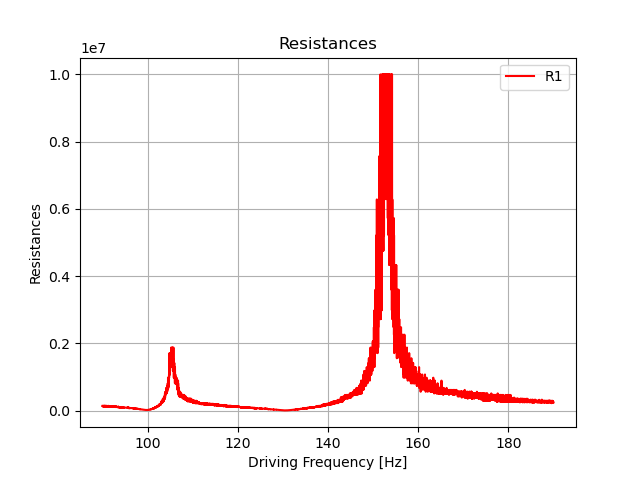

In [78]:
plt.figure()
plt.plot(frequencies_list, R1_opt_w_r1, "r-", label = "R1")
plt.xlabel("Driving Frequency [Hz]")
plt.ylabel("Resistances")
plt.title("Resistances")
plt.legend()
# plt.yscale('log')
plt.grid()
plt.show()